# Part A: Label-Efficiency Study

## 1. Introduction

The EuroSAT dataset contains 27,000 satellite images belonging to 10 land-use and land-cover classes. Deep learning models generally require sufficient labelled training data to achieve good classification performance. However, collecting and annotating large amounts of labelled satellite imagery can be time-consuming and costly.

This part of the project investigates how the amount of labelled training data affects the classification performance of a ResNet-50 model on the EuroSAT dataset. The main objective is to evaluate whether the model can maintain good performance when trained with progressively smaller subsets of the available training data.

The original EuroSAT paper by Helber et al. (2019) evaluates different training-test proportions using several classification approaches. In Table II, the ResNet-50 models are trained from scratch. The paper also investigates transfer learning with pretrained networks.

In its pretrained ResNet-50 experiment (Table III), the original paper uses a two-stage transfer-learning strategy. First, the final classification layer is trained while the pretrained backbone is kept fixed. The full network is then fine-tuned using a lower learning rate. The present study follows this general two-stage approach with an ImageNet-pretrained ResNet-50 model. The paper's Table II results, by contrast, are from ResNet-50 models trained from scratch.

For this study, five training-data proportions are considered: 10%, 30%, 50%, 70%, and 90% of the original training partition. The validation and test sets remain fixed across all experiments to ensure a consistent evaluation. Three random seeds are used for each training proportion to examine the stability of the results.

The experiments aim to answer the following research question:

**How does reducing the amount of labelled training data affect the classification accuracy and overall performance of an ImageNet-pretrained ResNet-50 model on the EuroSAT dataset?**

## 2. Experimental Setup
### 2.1 Mount Google Drive

Google Drive is mounted to access the EuroSAT dataset, the dataset split files, and the pretrained baseline model checkpoints.

The experimental outputs generated during Part A will also be saved to Google Drive to ensure that the results are preserved and can be accessed later.

In [16]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2.2 Import Libraries and Configure Paths

This section imports the required libraries and defines the paths to the EuroSAT dataset, the saved dataset splits, the baseline checkpoints, and the Part A experiment outputs.

The existing dataset and split files from the baseline experiment will be reused to ensure consistency across experiments.

All Part A results will be saved in the existing Part_A folder in Google Drive.

In [44]:
# --------------------------------------------------
# Google Drive project directory
# --------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/EuroSAT_Final_Experiments")

# --------------------------------------------------
# Dataset and split directories
# --------------------------------------------------

DATASET_DIR = PROJECT_DIR / "Shared" / "Dataset"
SPLITS_DIR = PROJECT_DIR / "Shared" / "Dataset_Splits"

# Verify required input directories
assert DATASET_DIR.is_dir(), f"Dataset not found: {DATASET_DIR}"
assert SPLITS_DIR.is_dir(), f"Splits folder not found: {SPLITS_DIR}"

# --------------------------------------------------
# Baseline folders
# --------------------------------------------------

BASELINE_DIR = PROJECT_DIR / "Baseline"
BASELINE_CHECKPOINT_DIR = BASELINE_DIR / "Checkpoints"

# --------------------------------------------------
# Part A folders
# --------------------------------------------------

PART_A_DIR = PROJECT_DIR / "Part_A"

PART_A_CHECKPOINT_DIR = PART_A_DIR / "Checkpoints"
PART_A_LOGS_DIR = PART_A_DIR / "Logs"
PART_A_RESULTS_DIR = PART_A_DIR / "Results"

# --------------------------------------------------
# Create Part A output folders if they do not exist
# --------------------------------------------------

PART_A_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PART_A_LOGS_DIR.mkdir(parents=True, exist_ok=True)
PART_A_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Display paths
# --------------------------------------------------

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())
print("Dataset splits directory:", SPLITS_DIR)
print("Baseline checkpoints:", BASELINE_CHECKPOINT_DIR)
print("Part A directory:", PART_A_DIR)

print("\nPart A output folders created/verified.")

Project directory: /content/drive/MyDrive/EuroSAT_Final_Experiments
Dataset directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset
Dataset exists: True
Dataset splits directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Shared/Dataset_Splits
Baseline checkpoints: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Checkpoints
Part A directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A

Part A output folders created/verified.


### 2.3 Load Dataset Splits

The dataset split information generated during the baseline experiment is loaded from Google Drive.

The existing training, validation, and test image assignments will be reused to ensure that the validation and test sets remain identical across all Part A experiments.

This maintains consistency between the baseline and the label-efficiency experiments.

In [18]:
# Load the existing dataset split and class mapping

SPLIT_FILE = SPLITS_DIR / "eurosat_splits.csv"
CLASS_MAPPING_FILE = SPLITS_DIR / "class_to_idx.json"

# Verify that the required files exist
assert SPLIT_FILE.exists(), f"Dataset split file not found: {SPLIT_FILE}"
assert CLASS_MAPPING_FILE.exists(), f"Class mapping file not found: {CLASS_MAPPING_FILE}"

# Load dataset splits
splits_df = pd.read_csv(SPLIT_FILE)

# Load class mapping
with open(CLASS_MAPPING_FILE, "r") as f:
    class_to_idx = json.load(f)

# Display basic information
print("Dataset splits loaded successfully!")
print("\nSplit file shape:", splits_df.shape)

print("\nColumns:")
print(splits_df.columns.tolist())

print("\nSplit distribution:")
print(splits_df["split"].value_counts())

print("\nNumber of classes:", len(class_to_idx))
print("\nClass mapping:")
print(class_to_idx)

Dataset splits loaded successfully!

Split file shape: (27000, 4)

Columns:
['relative_path', 'class_name', 'class_idx', 'split']

Split distribution:
split
train         19440
test           5400
validation     2160
Name: count, dtype: int64

Number of classes: 10

Class mapping:
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


### 2.4 Define Experiment Configuration

The experimental configuration is defined using the settings established in the baseline experiment.

The study evaluates five training data proportions (10%, 30%, 50%, 70%, and 90%) using three random seeds (42, 43, and 44).

The ResNet-50 architecture, ImageNet-pretrained weights, batch size, optimizer, learning rates, weight decay, and two-stage training schedule remain consistent with the baseline experiment.

The configuration ensures that the amount of training data is the primary variable investigated in this study.

In [19]:
# Experiment configuration

# Training data proportions
TRAINING_SHARES = [0.10, 0.30, 0.50, 0.70, 0.90]

# Random seeds
SEEDS = [42, 43, 44]

# Model configuration
MODEL_NAME = "ResNet50"
NUM_CLASSES = 10
PRETRAINED = True

# Training configuration (same as baseline)
BATCH_SIZE = 64
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 7
TOTAL_EPOCHS = HEAD_EPOCHS + FINETUNE_EPOCHS

# Optimizer configuration
OPTIMIZER_NAME = "AdamW"
HEAD_LR = 0.01
FINETUNE_LR = 0.0001
WEIGHT_DECAY = 0.0001

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Display configuration
print("Part A Experiment Configuration")
print("-" * 40)

print("Model:", MODEL_NAME)
print("Pretrained:", PRETRAINED)
print("Number of classes:", NUM_CLASSES)

print("\nTraining shares:", TRAINING_SHARES)
print("Random seeds:", SEEDS)

print("\nBatch size:", BATCH_SIZE)
print("Head training epochs:", HEAD_EPOCHS)
print("Fine-tuning epochs:", FINETUNE_EPOCHS)
print("Total epochs:", TOTAL_EPOCHS)

print("\nOptimizer:", OPTIMIZER_NAME)
print("Head learning rate:", HEAD_LR)
print("Fine-tuning learning rate:", FINETUNE_LR)
print("Weight decay:", WEIGHT_DECAY)

print("\nAvailable device:", DEVICE)

Part A Experiment Configuration
----------------------------------------
Model: ResNet50
Pretrained: True
Number of classes: 10

Training shares: [0.1, 0.3, 0.5, 0.7, 0.9]
Random seeds: [42, 43, 44]

Batch size: 64
Head training epochs: 3
Fine-tuning epochs: 7
Total epochs: 10

Optimizer: AdamW
Head learning rate: 0.01
Fine-tuning learning rate: 0.0001
Weight decay: 0.0001

Available device: cuda


### 2.5 Verify Baseline Files

This section verifies that the baseline model checkpoints and experiment results are accessible in Google Drive before starting Part A.

The existing baseline files will be reused for reference. The original baseline experiments will not be retrained.

In [20]:
# Verify baseline files in Google Drive

print("Checking baseline files...\n")

# Check baseline folders
folders_to_check = [
    BASELINE_CHECKPOINT_DIR,
    BASELINE_DIR / "Logs",
    BASELINE_DIR / "Results"
]

for folder in folders_to_check:
    print(f"{'FOUND' if folder.exists() else 'MISSING'}: {folder}")

# List checkpoint files
print("\nBaseline checkpoints:")
if BASELINE_CHECKPOINT_DIR.exists():
    for file in sorted(BASELINE_CHECKPOINT_DIR.iterdir()):
        print(" -", file.name)

# List result files
print("\nBaseline results:")
results_folder = BASELINE_DIR / "Results"

if results_folder.exists():
    for file in sorted(results_folder.iterdir()):
        print(" -", file.name)

# Verify important result files
required_files = [
    results_folder / "resnet50_test_results.csv",
    results_folder / "resnet50_test_summary.csv",
    results_folder / "resnet50_baseline_results_summary.csv"
]

print("\nRequired result file verification:")
for file in required_files:
    print(f"{'FOUND' if file.is_file() else 'MISSING'}: {file.name}")

Checking baseline files...

FOUND: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Checkpoints
FOUND: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Logs
FOUND: /content/drive/MyDrive/EuroSAT_Final_Experiments/Baseline/Results

Baseline checkpoints:
 - resnet50_seed_42.pth
 - resnet50_seed_43.pth
 - resnet50_seed_44.pth

Baseline results:
 - resnet50_baseline_results_summary.csv
 - resnet50_seed_42_classification_report.csv
 - resnet50_seed_42_confusion_matrix.csv
 - resnet50_seed_43_classification_report.csv
 - resnet50_seed_43_confusion_matrix.csv
 - resnet50_seed_44_classification_report.csv
 - resnet50_seed_44_confusion_matrix.csv
 - resnet50_test_results.csv
 - resnet50_test_summary.csv
 - resnet50_training_validation_accuracy.png
 - resnet50_training_validation_loss.png
 - resnet50_validation_results.csv
 - resnet50_validation_summary.csv

Required result file verification:
FOUND: resnet50_test_results.csv
FOUND: resnet50_test_summary.csv
FOUND: resnet50_base

## 3. Dataset Preparation and DataLoader Configuration
This section describes the preparation of the EuroSAT dataset for the training data efficiency experiments. The original dataset is divided into fixed training, validation, and test sets. Multiple training subsets are generated using stratified sampling with different training proportions and random seeds to evaluate the effect of training data availability on model performance. The subsets are verified to ensure reproducibility, class balance, and consistency. Finally, a custom PyTorch Dataset class, image transformations, and DataLoaders are configured for model training and evaluation.

### 3.1 Separate Training, Validation and Test Data

The previously saved dataset split is separated into training, validation, and test dataframes.

The original training data will be used to generate different training proportions, while the validation and test dataframes will remain fixed throughout the experiments.

In [21]:
# Separate the original dataset splits

train_df = splits_df[splits_df["split"] == "train"].copy().reset_index(drop=True)

val_df = splits_df[splits_df["split"] == "validation"].copy().reset_index(drop=True)

test_df = splits_df[splits_df["split"] == "test"].copy().reset_index(drop=True)

# Verify dataset sizes
print("Original dataset split sizes")
print("-" * 40)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nClass distribution in original training data:")
print(train_df["class_name"].value_counts().sort_index())

# Verify fixed validation and test sets
assert len(train_df) == 19440
assert len(val_df) == 2160
assert len(test_df) == 5400

print("\nAll dataset split checks passed!")

Original dataset split sizes
----------------------------------------
Training images: 19440
Validation images: 2160
Test images: 5400

Class distribution in original training data:
class_name
AnnualCrop              2160
Forest                  2160
HerbaceousVegetation    2160
Highway                 1800
Industrial              1800
Pasture                 1440
PermanentCrop           1800
Residential             2160
River                   1800
SeaLake                 2160
Name: count, dtype: int64

All dataset split checks passed!


### 3.2 Generate Training Subsets

Five training subsets are generated from the original training dataset, corresponding to 10%, 30%, 50%, 70%, and 90% of the available training images.

Stratified sampling is applied to preserve the class distribution within each subset.

For reproducibility, the sampling process uses the same three random seeds (42, 43, and 44) across all training proportions. Within each seed, the subsets are nested, meaning that smaller training subsets are contained within larger ones.

The validation and test datasets are not modified.

In [ ]:
# Generate stratified training subsets for all training shares and seeds

TRAINING_SUBSETS = {}

# Create a folder for saving training subset manifests
SUBSET_MANIFEST_DIR = PART_A_LOGS_DIR / "Training_Subsets"
SUBSET_MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

# Group training data by class
class_groups = {
    class_name: group.reset_index(drop=True)
    for class_name, group in train_df.groupby("class_name")
}

for seed in SEEDS:

    # Generate one reproducible shuffled order per class
    rng = np.random.default_rng(seed)

    shuffled_class_groups = {}

    for class_name, group in class_groups.items():
        shuffled_indices = rng.permutation(len(group))
        shuffled_class_groups[class_name] = group.iloc[
            shuffled_indices
        ].reset_index(drop=True)

    # Generate nested subsets for each training proportion
    for share in TRAINING_SHARES:

        subset_parts = []

        for class_name, shuffled_group in shuffled_class_groups.items():

            # Calculate the number of images for this class
            n_samples = round(len(shuffled_group) * share)

            # Select the first n images from the shuffled class
            class_subset = shuffled_group.iloc[:n_samples]

            subset_parts.append(class_subset)

        # Combine all class subsets
        subset_df = pd.concat(
            subset_parts,
            ignore_index=True
        )

        # Store subset using (training share, seed) as key
        TRAINING_SUBSETS[(share, seed)] = subset_df

        # Save subset manifest for reproducibility
        share_label = int(share * 100)

        manifest_path = (
            SUBSET_MANIFEST_DIR /
            f"training_subset_{share_label}pct_seed{seed}.csv"
        )

        subset_df.to_csv(manifest_path, index=False)

        print(
            f"Training share: {share_label}% | "
            f"Seed: {seed} | "
            f"Images: {len(subset_df)}"
        )

print("\nAll training subsets generated successfully!")

Training share: 10% | Seed: 42 | Images: 1944
Training share: 30% | Seed: 42 | Images: 5832
Training share: 50% | Seed: 42 | Images: 9720
Training share: 70% | Seed: 42 | Images: 13608
Training share: 90% | Seed: 42 | Images: 17496
Training share: 10% | Seed: 43 | Images: 1944
Training share: 30% | Seed: 43 | Images: 5832
Training share: 50% | Seed: 43 | Images: 9720
Training share: 70% | Seed: 43 | Images: 13608
Training share: 90% | Seed: 43 | Images: 17496
Training share: 10% | Seed: 44 | Images: 1944
Training share: 30% | Seed: 44 | Images: 5832
Training share: 50% | Seed: 44 | Images: 9720
Training share: 70% | Seed: 44 | Images: 13608
Training share: 90% | Seed: 44 | Images: 17496

All training subsets generated successfully!


### 3.3 Verify Training Subsets and Fixed Validation/Test Sets

The generated training subsets are verified to ensure that the expected number of images is selected for each training proportion and random seed.

The class distribution, image paths, and subset sizes are checked to confirm that stratified sampling has been applied correctly.

Additionally, the validation and test datasets are verified to remain identical across all experiments. This ensures consistency and fairness in model evaluation.

In [ ]:
# Verify all generated training subsets

print("TRAINING SUBSET VERIFICATION")
print("=" * 65)

for seed in SEEDS:
    print(f"\nSeed: {seed}")
    print("-" * 65)

    previous_subset_paths = None

    for share in TRAINING_SHARES:
        subset_df = TRAINING_SUBSETS[(share, seed)]

        # Calculate expected total subset size
        expected_count = sum(
            round(len(group) * share)
            for group in class_groups.values()
        )

        actual_count = len(subset_df)

        # Check expected subset size
        assert actual_count == expected_count, (
            f"Incorrect subset size for {share} and seed {seed}"
        )

        # Check for duplicate image paths
        assert subset_df["relative_path"].is_unique, (
            f"Duplicate image paths found for {share} and seed {seed}"
        )

        # Check class coverage
        assert set(subset_df["class_name"]) == set(class_to_idx.keys()), (
            f"Missing classes for {share} and seed {seed}"
        )

        # Verify exact class counts (stratified sampling)
        for class_name, group in class_groups.items():

            expected_class_count = round(len(group) * share)

            actual_class_count = (
                subset_df["class_name"] == class_name
            ).sum()

            assert actual_class_count == expected_class_count, (
                f"Incorrect class count for {class_name}, "
                f"{share} share, seed {seed}"
            )

        # Check nested subsets
        current_paths = set(subset_df["relative_path"])

        if previous_subset_paths is not None:
            assert previous_subset_paths.issubset(current_paths), (
                f"Nested subset check failed for seed {seed}"
            )

        previous_subset_paths = current_paths

        print(
            f"{int(share * 100):>3}% training share | "
            f"{actual_count:>5} images | "
            f"{subset_df['class_name'].nunique()} classes | "
            f"Checks passed"
        )


# Verify fixed validation and test sets

print("\nFIXED VALIDATION AND TEST SET VERIFICATION")
print("=" * 65)

# Check dataset sizes
assert len(val_df) == 2160
assert len(test_df) == 5400

# Check duplicate image paths
assert val_df["relative_path"].is_unique
assert test_df["relative_path"].is_unique

# Check no overlap between validation and test
assert set(val_df["relative_path"]).isdisjoint(
    set(test_df["relative_path"])
)

# Check no overlap between training and validation
assert set(train_df["relative_path"]).isdisjoint(
    set(val_df["relative_path"])
)

# Check no overlap between training and test
assert set(train_df["relative_path"]).isdisjoint(
    set(test_df["relative_path"])
)

print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Validation and test sets remain fixed.")
print("No overlap between original dataset splits.")

print("\nAll subset and split verification checks passed!")

TRAINING SUBSET VERIFICATION

Seed: 42
-----------------------------------------------------------------
 10% training share |  1944 images | 10 classes | Checks passed
 30% training share |  5832 images | 10 classes | Checks passed
 50% training share |  9720 images | 10 classes | Checks passed
 70% training share | 13608 images | 10 classes | Checks passed
 90% training share | 17496 images | 10 classes | Checks passed

Seed: 43
-----------------------------------------------------------------
 10% training share |  1944 images | 10 classes | Checks passed
 30% training share |  5832 images | 10 classes | Checks passed
 50% training share |  9720 images | 10 classes | Checks passed
 70% training share | 13608 images | 10 classes | Checks passed
 90% training share | 17496 images | 10 classes | Checks passed

Seed: 44
-----------------------------------------------------------------
 10% training share |  1944 images | 10 classes | Checks passed
 30% training share |  5832 images | 10

### 3.4 Define Dataset and Image Transformations

A custom PyTorch Dataset class is used to load EuroSAT images and their corresponding class labels from the saved dataset split.

The image preprocessing follows the same approach as the baseline experiment, including conversion to RGB, tensor conversion, and ImageNet normalization.

The same preprocessing is applied consistently across the training, validation, and test datasets to maintain comparability with the baseline experiment.

In [22]:
from PIL import Image
from torch.utils.data import Dataset

# ImageNet normalization values used in the baseline
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class EuroSATDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = self.root_dir / row["relative_path"]

        image = Image.open(image_path).convert("RGB")
        label = int(row["class_idx"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


print("EuroSAT Dataset class defined successfully.")

EuroSAT Dataset class defined successfully.


### 3.5 Create DataLoaders for Training, Validation and Testing

PyTorch DataLoaders are created to efficiently load the training, validation, and test images in batches.

For each experiment, the training DataLoader uses the corresponding training subset generated for the selected data proportion and random seed.

The validation and test DataLoaders use the same fixed datasets across all experiments.

A batch size of 64 is maintained to remain consistent with the baseline experiment. The training DataLoader shuffles the training images, while validation and test DataLoaders preserve their order.

In [ ]:
# Create DataLoaders

from torch.utils.data import DataLoader
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def create_dataloaders(train_subset_df, seed):

    train_dataset = EuroSATDataset(
        train_subset_df,
        DATASET_DIR,
        transform=image_transform
    )

    val_dataset = EuroSATDataset(
        val_df,
        DATASET_DIR,
        transform=image_transform
    )

    test_dataset = EuroSATDataset(
        test_df,
        DATASET_DIR,
        transform=image_transform
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader, test_loader


print("DataLoader function updated successfully!")
print("Number of workers: 0")
print("Device:", DEVICE)


DataLoader function updated successfully!
Number of workers: 0
Device: cuda


## 4. Model Training

The ImageNet-pretrained ResNet-50 model from the baseline experiment is used for the Part A label-efficiency study.

The model follows the same two-stage training strategy as the baseline. Initially, the backbone is frozen while the final classification layer is trained. Subsequently, the entire network is fine-tuned using the EuroSAT training subset.

The training procedure and hyperparameters remain consistent with the baseline to ensure a fair comparison across different training data proportions.

### 4.1 Load the Pretrained ResNet-50 Model

The ResNet-50 architecture is initialized with ImageNet-pretrained weights. The final fully connected layer is replaced with a new classification layer containing 10 output neurons corresponding to the EuroSAT classes.

During the initial training stage, the backbone parameters are frozen and only the classification layer is trained.

In [ ]:
# Load ImageNet-pretrained ResNet-50

import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

def create_resnet50_model(num_classes=NUM_CLASSES):

    # Load ImageNet-pretrained ResNet-50
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

    # Freeze all backbone parameters
    for param in model.parameters():
        param.requires_grad = False

    # Replace the final classification layer
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    # Move model to the selected device
    model = model.to(DEVICE)

    return model


print("ResNet-50 model creation function defined.")
print("Pretrained weights: ImageNet")
print("Number of output classes:", NUM_CLASSES)
print("Device:", DEVICE)

ResNet-50 model creation function defined.
Pretrained weights: ImageNet
Number of output classes: 10
Device: cuda


### 4.2 Define the Training and Validation Functions

Training and validation functions are defined to implement the two-stage training procedure used in the baseline experiment.

The first stage trains only the final classification layer while keeping the pretrained backbone frozen. The second stage fine-tunes the entire ResNet-50 model using the selected training subset.

The AdamW optimizer and baseline hyperparameters are maintained throughout the experiments. Validation performance is monitored after each epoch to record the model's progress and identify the best-performing checkpoint.

In [ ]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(
    model,
    dataloader,
    optimizer,
    criterion,
    device,
    train_head_only=False
):
    model.train()

    # Keep the backbone, including BatchNorm layers, in evaluation mode
    # when training only the classification head.
    if train_head_only:
        model.eval()
        model.fc.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def evaluate_model(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

### 4.3 Implement the Two-Stage Training Procedure

A two-stage training procedure is implemented to maintain consistency with the ResNet-50 baseline experiment.

In the first stage, the pretrained backbone remains frozen while the final classification layer is trained for 3 epochs using the AdamW optimizer.

In the second stage, all model parameters are unfrozen and the entire network is fine-tuned for another 7 epochs using the baseline fine-tuning learning rate.

The model is evaluated on the fixed validation dataset after every epoch. The checkpoint with the highest validation accuracy is retained for subsequent testing.

Training history, including training loss, validation loss, training accuracy, and validation accuracy, is recorded for each experiment.

In [ ]:
# Two-stage ResNet-50 training procedure

def train_resnet50_experiment(
    train_loader,
    val_loader,
    training_share,
    seed
):
    """
    Train ImageNet-pretrained ResNet-50 using the baseline
    two-stage training procedure.

    Stage 1: Train classification head for 3 epochs.
    Stage 2: Fine-tune the entire network for 7 epochs.

    The best checkpoint is selected using validation accuracy.
    """

    # 1. Set reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create a fresh pretrained model
    model = create_resnet50_model(NUM_CLASSES)

    history = []
    best_val_accuracy = -1.0
    best_epoch = None
    best_model_state = None

    experiment_name = (
        f"resnet50_{int(training_share * 100)}pct_seed{seed}"
    )

    print(f"\nStarting experiment: {experiment_name}")
    print("-" * 60)

    # 2. Stage 1: Train classification head
    print("\nStage 1: Training classification head")

    for param in model.parameters():
        param.requires_grad = False

    for param in model.fc.parameters():
        param.requires_grad = True

    optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=HEAD_LR,
        weight_decay=WEIGHT_DECAY
    )

    for epoch in range(1, HEAD_EPOCHS + 1):

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, optimizer,
            criterion, DEVICE, train_head_only=True
        )

        val_loss, val_accuracy = evaluate_model(
            model, val_loader, criterion, DEVICE
        )

        history.append({
            "training_share": training_share,
            "seed": seed,
            "stage": "head_training",
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy
        })

        print(
            f"Head Epoch [{epoch}/{HEAD_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # 3. Stage 2: Fine-tune entire network
    print("\nStage 2: Fine-tuning the entire network")

    for param in model.parameters():
        param.requires_grad = True

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=WEIGHT_DECAY
    )

    for epoch in range(1, FINETUNE_EPOCHS + 1):

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, optimizer,
            criterion, DEVICE
        )

        val_loss, val_accuracy = evaluate_model(
            model, val_loader, criterion, DEVICE
        )

        total_epoch = HEAD_EPOCHS + epoch

        history.append({
            "training_share": training_share,
            "seed": seed,
            "stage": "fine_tuning",
            "epoch": total_epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy
        })

        print(
            f"Fine-tuning Epoch [{epoch}/{FINETUNE_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = total_epoch

            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # 4. Restore best checkpoint
    model.load_state_dict(best_model_state)

    # 5. Save best model checkpoint
    checkpoint_path = (
        PART_A_CHECKPOINT_DIR /
        f"{experiment_name}_best.pth"
    )

    torch.save(
        {
            "model_state_dict": best_model_state,
            "training_share": training_share,
            "seed": seed,
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch,
            "model_name": MODEL_NAME,
            "pretrained": PRETRAINED
        },
        checkpoint_path
    )

    # 6. Save training history
    history_df = pd.DataFrame(history)

    history_path = (
        PART_A_LOGS_DIR /
        f"{experiment_name}_history.csv"
    )

    history_df.to_csv(history_path, index=False)

    print("\nExperiment completed:", experiment_name)
    print(f"Best validation accuracy: {best_val_accuracy:.4f}")
    print(f"Best epoch: {best_epoch}")
    print("Checkpoint saved:", checkpoint_path)
    print("Training history saved:", history_path)

    return model, history_df, best_val_accuracy


# Final confirmation: function definition completed

print("=" * 60)
print("SUCCESS: Two-stage ResNet-50 training function defined!")
print("=" * 60)
print(f"Stage 1: Classification head training - {HEAD_EPOCHS} epochs")
print(f"Stage 2: Full network fine-tuning - {FINETUNE_EPOCHS} epochs")
print(f"Optimizer: {OPTIMIZER_NAME}")
print(f"Device: {DEVICE}")
print("Checkpoint saving: Configured")
print("Training history saving: Configured")
print("\nSection 4.3 completed successfully!")

SUCCESS: Two-stage ResNet-50 training function defined!
Stage 1: Classification head training - 3 epochs
Stage 2: Full network fine-tuning - 7 epochs
Optimizer: AdamW
Device: cuda
Checkpoint saving: Configured
Training history saving: Configured

Section 4.3 completed successfully!


### 4.4 Run the Pipeline Test

Before conducting the full label-efficiency experiments, a preliminary pipeline test is performed to verify the complete two-stage training workflow.

The test uses the 10% training subset with random seed 42 and a reduced training schedule consisting of one epoch for classification head training and one epoch for fine-tuning.

The test verifies model initialization, both training stages, validation evaluation, checkpoint saving, and training history generation.

The pipeline test outputs are saved separately from the final experiment outputs to avoid overwriting any experimental checkpoints or results.

This preliminary test is intended to identify implementation issues before running the complete set of label-efficiency experiments.

In [ ]:
# Preliminary two-stage pipeline test

PIPELINE_TEST_SHARE = 0.10
PIPELINE_TEST_SEED = 42

# Reduced schedule for testing both training stages
PIPELINE_HEAD_EPOCHS = 1
PIPELINE_FINETUNE_EPOCHS = 1

print("Starting Part A Two-Stage Pipeline Test")
print("=" * 60)

# --------------------------------------------------
# 1. Set reproducibility
# --------------------------------------------------

random.seed(PIPELINE_TEST_SEED)
np.random.seed(PIPELINE_TEST_SEED)
torch.manual_seed(PIPELINE_TEST_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(PIPELINE_TEST_SEED)

print("Device:", DEVICE)

# --------------------------------------------------
# 2. Load the 10% training subset
# --------------------------------------------------

train_subset_df = TRAINING_SUBSETS[
    (PIPELINE_TEST_SHARE, PIPELINE_TEST_SEED)
]

# Create DataLoaders
train_loader, val_loader, _ = create_dataloaders(
    train_subset_df,
    PIPELINE_TEST_SEED
)

print("Training images:", len(train_subset_df))
print("Validation images:", len(val_df))

# --------------------------------------------------
# 3. Initialize pretrained ResNet-50
# --------------------------------------------------

model = create_resnet50_model(NUM_CLASSES)

history = []

best_val_accuracy = -1.0
best_model_state = None
best_epoch = None

# --------------------------------------------------
# 4. Stage 1: Train classification head
# --------------------------------------------------

print("\nStage 1: Training classification head")

# Freeze the complete backbone
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final classification layer
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY
)

for epoch in range(1, PIPELINE_HEAD_EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        DEVICE,
        train_head_only=True
    )

    val_loss, val_accuracy = evaluate_model(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    history.append({
        "stage": "head_training",
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy
    })

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Head Epoch {epoch}/{PIPELINE_HEAD_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# --------------------------------------------------
# 5. Stage 2: Fine-tune the entire network
# --------------------------------------------------

print("\nStage 2: Fine-tuning the entire network")

# Unfreeze the complete network
for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=FINETUNE_LR,
    weight_decay=WEIGHT_DECAY
)

for epoch in range(1, PIPELINE_FINETUNE_EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        DEVICE
    )

    val_loss, val_accuracy = evaluate_model(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    total_epoch = PIPELINE_HEAD_EPOCHS + epoch

    history.append({
        "stage": "fine_tuning",
        "epoch": total_epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy
    })

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = total_epoch

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Fine-tuning Epoch {epoch}/{PIPELINE_FINETUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# --------------------------------------------------
# 6. Save pipeline test outputs separately
# --------------------------------------------------

pipeline_dir = PART_A_DIR / "Pipeline_Test"
pipeline_dir.mkdir(parents=True, exist_ok=True)

history_df = pd.DataFrame(history)

history_df.to_csv(
    pipeline_dir / "pipeline_test_history.csv",
    index=False
)

# Save the best validation checkpoint
torch.save(
    {
        "model_state_dict": best_model_state,
        "training_share": PIPELINE_TEST_SHARE,
        "seed": PIPELINE_TEST_SEED,
        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,
        "model_name": MODEL_NAME,
        "pretrained": PRETRAINED,
        "pipeline_test": True
    },
    pipeline_dir / "pipeline_test_model.pth"
)

# --------------------------------------------------
# 7. Display pipeline test summary
# --------------------------------------------------

print("\nPipeline test completed.")
print("Training images:", len(train_subset_df))
print("Validation images:", len(val_df))
print("Training stages: Head training + Fine-tuning")
print("Total test epochs:", len(history_df))
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print("Best epoch:", best_epoch)
print("Training history saved:", pipeline_dir / "pipeline_test_history.csv")
print("Checkpoint saved:", pipeline_dir / "pipeline_test_model.pth")

Starting Part A Two-Stage Pipeline Test
Device: cuda
Training images: 1944
Validation images: 2160

Stage 1: Training classification head
Head Epoch 1/1 | Train Loss: 0.8167 | Val Loss: 0.5349 | Train Acc: 0.7783 | Val Acc: 0.8722

Stage 2: Fine-tuning the entire network
Fine-tuning Epoch 1/1 | Train Loss: 0.7782 | Val Loss: 0.4141 | Train Acc: 0.7665 | Val Acc: 0.8699

Pipeline test completed.
Training images: 1944
Validation images: 2160
Training stages: Head training + Fine-tuning
Total test epochs: 2
Best validation accuracy: 0.8722
Best epoch: 1
Training history saved: /content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Pipeline_Test/pipeline_test_history.csv
Checkpoint saved: /content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Pipeline_Test/pipeline_test_model.pth


### 4.5 Run the Full Label-Efficiency Experiments

After successfully verifying the training pipeline, the complete label-efficiency experiments are conducted.

The pretrained ResNet-50 model is trained using five different training data proportions: 10%, 30%, 50%, 70%, and 90%.

Each training proportion is evaluated using three random seeds (42, 43, and 44), resulting in 15 experiments.

Each experiment follows the same two-stage training procedure as the baseline, consisting of 3 epochs of classification head training followed by 7 epochs of full network fine-tuning.

The best model checkpoint for each experiment is selected based on validation accuracy. Training histories and model checkpoints are saved separately for each experiment.

A checkpoint-based resume mechanism is implemented to avoid repeating successfully completed experiments if the execution session is interrupted. The combined experiment summary and training history are updated after each completed experiment.

In [ ]:
# Run all Part A label-efficiency experiments
# Includes checkpoint validation and resume functionality

ALL_EXPERIMENT_RESULTS = []
ALL_TRAINING_HISTORIES = []

EXPECTED_EPOCHS = HEAD_EPOCHS + FINETUNE_EPOCHS

print("Starting Full Part A Experiments")
print("=" * 65)


# --------------------------------------------------
# 1. Check whether an experiment is already complete
# --------------------------------------------------

def is_experiment_complete(training_share, seed):

    experiment_name = (
        f"resnet50_{int(training_share * 100)}pct_seed{seed}"
    )

    checkpoint_path = (
        PART_A_CHECKPOINT_DIR /
        f"{experiment_name}_best.pth"
    )

    history_path = (
        PART_A_LOGS_DIR /
        f"{experiment_name}_history.csv"
    )

    # Both files must exist
    if not checkpoint_path.exists() or not history_path.exists():
        return False

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        history_df = pd.read_csv(history_path)

        # Verify checkpoint metadata
        if checkpoint["seed"] != seed:
            return False

        if not np.isclose(
            checkpoint["training_share"], training_share
        ):
            return False

        if "model_state_dict" not in checkpoint:
            return False

        if not np.isfinite(checkpoint["best_val_accuracy"]):
            return False

        # Verify training history
        if len(history_df) != EXPECTED_EPOCHS:
            return False

        expected_epochs = list(range(1, EXPECTED_EPOCHS + 1))

        if sorted(history_df["epoch"].tolist()) != expected_epochs:
            return False

        if not history_df["val_accuracy"].notna().all():
            return False

        return True

    except Exception as error:
        print(
            f"Existing output is incomplete or invalid: "
            f"{experiment_name}"
        )
        print("Reason:", error)
        return False


# --------------------------------------------------
# 2. Save combined outputs after each experiment
# --------------------------------------------------

def save_experiment_progress():

    experiment_results = []
    training_histories = []

    for share in TRAINING_SHARES:

        for seed in SEEDS:

            if is_experiment_complete(share, seed):

                experiment_name = (
                    f"resnet50_{int(share * 100)}pct_seed{seed}"
                )

                checkpoint_path = (
                    PART_A_CHECKPOINT_DIR /
                    f"{experiment_name}_best.pth"
                )

                history_path = (
                    PART_A_LOGS_DIR /
                    f"{experiment_name}_history.csv"
                )

                checkpoint = torch.load(
                    checkpoint_path,
                    map_location="cpu",
                    weights_only=True
                )

                history_df = pd.read_csv(history_path)

                train_subset_df = TRAINING_SUBSETS[(share, seed)]

                experiment_results.append({
                    "training_share": share,
                    "seed": seed,
                    "training_images": len(train_subset_df),
                    "best_val_accuracy": checkpoint[
                        "best_val_accuracy"
                    ],
                    "best_epoch": checkpoint["best_epoch"]
                })

                training_histories.append(history_df)

    # Save the latest available experiment summary
    experiment_summary_df = pd.DataFrame(experiment_results)

    experiment_summary_df.to_csv(
        PART_A_RESULTS_DIR / "part_a_validation_summary.csv",
        index=False
    )

    # Save the latest available combined training history
    if training_histories:

        combined_history_df = pd.concat(
            training_histories,
            ignore_index=True
        )

        combined_history_df.to_csv(
            PART_A_LOGS_DIR / "part_a_combined_training_history.csv",
            index=False
        )

    print(
        f"\nProgress saved: "
        f"{len(experiment_summary_df)}/{len(TRAINING_SHARES) * len(SEEDS)} "
        "experiments completed."
    )


# --------------------------------------------------
# 3. Run all training shares and random seeds
# --------------------------------------------------

for share in TRAINING_SHARES:

    for seed in SEEDS:

        experiment_name = (
            f"resnet50_{int(share * 100)}pct_seed{seed}"
        )

        print("\n" + "=" * 65)
        print(f"Training Share: {share * 100:.0f}% | Seed: {seed}")
        print("=" * 65)

        # Skip experiments that are already completed
        if is_experiment_complete(share, seed):

            print(
                f"Skipping {experiment_name}: "
                "valid checkpoint and history already exist."
            )

            continue

        print("Experiment not completed. Starting training...")

        # Get the corresponding training subset
        train_subset_df = TRAINING_SUBSETS[(share, seed)]

        # Create training and validation DataLoaders
        train_loader, val_loader, _ = create_dataloaders(
            train_subset_df,
            seed
        )

        # Train using the baseline two-stage procedure
        model, history_df, best_val_accuracy = (
            train_resnet50_experiment(
                train_loader=train_loader,
                val_loader=val_loader,
                training_share=share,
                seed=seed
            )
        )

        print(f"\nFinished: {experiment_name}")
        print(f"Best validation accuracy: {best_val_accuracy:.4f}")

        # Release memory
        del model
        del train_loader
        del val_loader

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Save updated progress immediately
        save_experiment_progress()


# --------------------------------------------------
# 4. Display final experiment progress
# --------------------------------------------------

save_experiment_progress()

final_summary_df = pd.read_csv(
    PART_A_RESULTS_DIR / "part_a_validation_summary.csv"
)

print("\nPart A experiment execution finished.")
print("\nExperiment summary:")
print(final_summary_df)

print(
    "\nCompleted experiments:",
    len(final_summary_df),
    "/",
    len(TRAINING_SHARES) * len(SEEDS)
)


Starting Full Part A Experiments

Training Share: 10% | Seed: 42
Skipping resnet50_10pct_seed42: valid checkpoint and history already exist.

Training Share: 10% | Seed: 43
Experiment not completed. Starting training...

Starting experiment: resnet50_10pct_seed43
------------------------------------------------------------

Stage 1: Training classification head
Head Epoch [1/3] Train Loss: 0.7302 | Val Loss: 0.5407 | Train Acc: 0.7870 | Val Acc: 0.8708
Head Epoch [2/3] Train Loss: 0.1265 | Val Loss: 0.5644 | Train Acc: 0.9522 | Val Acc: 0.8759
Head Epoch [3/3] Train Loss: 0.0385 | Val Loss: 0.5090 | Train Acc: 0.9882 | Val Acc: 0.8921

Stage 2: Fine-tuning the entire network
Fine-tuning Epoch [1/7] Train Loss: 0.8544 | Val Loss: 0.4749 | Train Acc: 0.7299 | Val Acc: 0.8569
Fine-tuning Epoch [2/7] Train Loss: 0.1300 | Val Loss: 0.3638 | Train Acc: 0.9666 | Val Acc: 0.8898
Fine-tuning Epoch [3/7] Train Loss: 0.0474 | Val Loss: 0.3596 | Train Acc: 0.9861 | Val Acc: 0.9028
Fine-tuning Epoc

## 5. Evaluation

The trained ResNet-50 models are evaluated using the fixed test dataset containing 5,400 images.

The best model checkpoint selected using validation accuracy is loaded for each training proportion and random seed.

The evaluation uses accuracy, macro precision, macro recall, and macro F1-score to assess classification performance across the different training data proportions.

The same test images are used for all experiments to ensure consistent evaluation.

### 5.1 Load the Best Model Checkpoints

The best model checkpoints saved during the training experiments are loaded for evaluation.

Each checkpoint corresponds to a specific training data proportion and random seed. The saved model weights are restored to evaluate the corresponding experiment on the fixed test dataset.

In [30]:
# Define function to load a trained ResNet-50 checkpoint

def load_part_a_checkpoint(training_share, seed):

    share_label = int(training_share * 100)

    checkpoint_path = (
        PART_A_CHECKPOINT_DIR /
        f"resnet50_{share_label}pct_seed{seed}_best.pth"
    )

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    # Create the ResNet-50 architecture
    # Pretrained weights are not downloaded again because
    # the checkpoint already contains the complete model weights.
    model = resnet50(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model


print("Checkpoint loading function defined successfully.")
print("Checkpoint directory:", PART_A_CHECKPOINT_DIR)

Checkpoint loading function defined successfully.
Checkpoint directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Checkpoints



### 5.1.1 Prepare a Separate Output Directory for Final Test Evaluation

Before evaluating the trained models on the fixed test set, a separate output directory is created to store the final evaluation results.

This ensures that the previously generated validation results, training histories, and model checkpoints remain unchanged.

The evaluation outputs are stored separately from the original experiment results. The GPU availability is also verified before starting the evaluation.

**Purpose:**
- Preserve existing validation results and training outputs.
- Store final test results in a dedicated directory.
- Avoid accidentally overwriting previously generated files.
- Verify GPU availability before evaluation.

The trained checkpoints are loaded for inference only. No additional model training is performed in this stage.


In [29]:
# ============================================================
# 5.1.1 Prepare Output Directory for Final Test Evaluation
# ============================================================

# Dedicated directory for final Part A test evaluation
PART_A_RESULTS_DIR = (
    PART_A_DIR
    / "Results"
    / "Final_Test_Evaluation_GPU_2026-11-05_Run2"
)

# Create the directory if it does not already exist
PART_A_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Verify available hardware
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Evaluation will use CPU.")

print("Final test evaluation directory:", PART_A_RESULTS_DIR)
print("Output directory ready.")


GPU: Tesla T4
New results directory: /content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Results/Final_Test_Evaluation_GPU_2026-11-05_Run2
Existing results are protected.


### 5.2 Evaluate Models on the Fixed Test Set

Each trained model is evaluated using the same fixed test dataset.

For every training data proportion and random seed, the corresponding best validation checkpoint is loaded and used to generate predictions on the test images.

Accuracy, macro precision, macro recall, and macro F1-score are calculated for each experiment. Classification reports and confusion matrices are also generated to provide a detailed assessment of class-wise performance.

Evaluation results and supporting reports are saved after each completed experiment. This allows the evaluation process to resume without repeating experiments whose test results have already been saved.

In [38]:

# ============================================================
# 5.2 Evaluate All Part A Experiments on the Fixed Test Set
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from torch.utils.data import DataLoader


# ============================================================
# 1. Define Class Names in the Correct Numerical Order
# ============================================================

CLASS_NAMES = [
    name
    for name, idx in sorted(
        class_to_idx.items(),
        key=lambda item: item[1]
    )
]


# ============================================================
# 2. Create the Fixed Test Dataset and DataLoader
# ============================================================

# Use the permanent Google Drive dataset directory
test_dataset = EuroSATDataset(
    dataframe=test_df,
    root_dir=DATASET_DIR,
    transform=image_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Fixed test dataset created successfully.")
print("Test images:", len(test_dataset))
print("Dataset location:", DATASET_DIR)
print("Device:", DEVICE)

assert len(test_dataset) == 5400, (
    f"Expected 5400 test images, found {len(test_dataset)}"
)


# ============================================================
# 3. Create Output Directories
# ============================================================

CLASSIFICATION_REPORT_DIR = (
    PART_A_RESULTS_DIR / "Classification_Reports"
)

CONFUSION_MATRIX_DIR = (
    PART_A_RESULTS_DIR / "Confusion_Matrices"
)

CLASSIFICATION_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CONFUSION_MATRIX_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 4. Load Previously Saved Evaluation Results
# ============================================================

PART_A_TEST_RESULTS_FILE = (
    PART_A_RESULTS_DIR / "part_a_test_results.csv"
)

if PART_A_TEST_RESULTS_FILE.exists():

    existing_results_df = pd.read_csv(
        PART_A_TEST_RESULTS_FILE
    )

    PART_A_TEST_RESULTS = (
        existing_results_df.to_dict("records")
    )

else:

    PART_A_TEST_RESULTS = []


# ============================================================
# 5. Identify Experiments with All Evaluation Files Saved
# ============================================================

completed_experiments = set()

for row in PART_A_TEST_RESULTS:

    share = round(
        float(row["training_share"]),
        2
    )

    seed = int(row["seed"])

    share_label = int(share * 100)

    report_path = (
        CLASSIFICATION_REPORT_DIR /
        f"classification_report_{share_label}pct_seed{seed}.csv"
    )

    cm_path = (
        CONFUSION_MATRIX_DIR /
        f"confusion_matrix_{share_label}pct_seed{seed}.csv"
    )

    if report_path.exists() and cm_path.exists():

        completed_experiments.add(
            (share, seed)
        )


# Storage for the current notebook session

CLASSIFICATION_REPORTS = {}
CONFUSION_MATRICES = {}


# ============================================================
# 6. Evaluate Every Training Share and Seed
# ============================================================

for share in TRAINING_SHARES:

    for seed in SEEDS:

        share_label = int(share * 100)

        experiment_key = (
            round(float(share), 2),
            int(seed)
        )

        print("\n" + "=" * 65)

        print(
            f"Evaluating {share_label}% training share | Seed {seed}"
        )

        print("=" * 65)


        # ----------------------------------------------------
        # Skip Only Fully Completed Evaluations
        # ----------------------------------------------------

        if experiment_key in completed_experiments:

            print(
                "Evaluation results, classification report, "
                "and confusion matrix already exist. Skipping."
            )

            continue


        # ----------------------------------------------------
        # Load the Best Validation Checkpoint
        # ----------------------------------------------------

        model = load_part_a_checkpoint(
            share,
            seed
        )

        model.eval()


        # ----------------------------------------------------
        # Generate Predictions on the Fixed Test Set
        # ----------------------------------------------------

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(DEVICE)

                outputs = model(images)

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                all_labels.extend(
                    labels.numpy()
                )

                all_predictions.extend(
                    predictions.cpu().numpy()
                )


        # ----------------------------------------------------
        # Calculate Evaluation Metrics
        # ----------------------------------------------------

        accuracy = accuracy_score(
            all_labels,
            all_predictions
        )

        precision = precision_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )

        f1 = f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )


        # ----------------------------------------------------
        # Generate Classification Report
        # ----------------------------------------------------

        report = classification_report(
            all_labels,
            all_predictions,
            labels=list(range(NUM_CLASSES)),
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )


        # ----------------------------------------------------
        # Generate Confusion Matrix
        # ----------------------------------------------------

        cm = confusion_matrix(
            all_labels,
            all_predictions,
            labels=list(range(NUM_CLASSES))
        )


        # ----------------------------------------------------
        # Store Experiment Results
        # ----------------------------------------------------

        experiment_result = {
            "training_share": share,
            "seed": seed,
            "test_accuracy": accuracy,
            "macro_precision": precision,
            "macro_recall": recall,
            "macro_f1": f1
        }


        # ----------------------------------------------------
        # Remove an Incomplete Previous Record
        # ----------------------------------------------------

        PART_A_TEST_RESULTS = [
            row
            for row in PART_A_TEST_RESULTS
            if not (
                round(
                    float(row["training_share"]),
                    2
                ) == round(float(share), 2)
                and int(row["seed"]) == int(seed)
            )
        ]

        PART_A_TEST_RESULTS.append(
            experiment_result
        )


        # ----------------------------------------------------
        # Save Test Results Immediately
        # ----------------------------------------------------

        part_a_results_df = pd.DataFrame(
            PART_A_TEST_RESULTS
        )

        part_a_results_df.to_csv(
            PART_A_TEST_RESULTS_FILE,
            index=False
        )


        # ----------------------------------------------------
        # Save Classification Report Immediately
        # ----------------------------------------------------

        report_df = pd.DataFrame(
            report
        ).transpose()

        report_path = (
            CLASSIFICATION_REPORT_DIR /
            f"classification_report_{share_label}pct_seed{seed}.csv"
        )

        report_df.to_csv(
            report_path
        )


        # ----------------------------------------------------
        # Save Confusion Matrix Immediately
        # ----------------------------------------------------

        cm_df = pd.DataFrame(
            cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        )

        cm_path = (
            CONFUSION_MATRIX_DIR /
            f"confusion_matrix_{share_label}pct_seed{seed}.csv"
        )

        cm_df.to_csv(
            cm_path
        )


        # ----------------------------------------------------
        # Store Current Session Outputs
        # ----------------------------------------------------

        CLASSIFICATION_REPORTS[
            (share, seed)
        ] = report

        CONFUSION_MATRICES[
            (share, seed)
        ] = cm

        completed_experiments.add(
            experiment_key
        )


        # ----------------------------------------------------
        # Display Evaluation Metrics
        # ----------------------------------------------------

        print(f"Test Accuracy: {accuracy:.4f}")
        print(f"Macro Precision: {precision:.4f}")
        print(f"Macro Recall: {recall:.4f}")
        print(f"Macro F1-score: {f1:.4f}")

        print("Evaluation results saved successfully.")


        # ----------------------------------------------------
        # Release Memory
        # ----------------------------------------------------

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 7. Display Evaluation Progress
# ============================================================

expected_experiments = (
    len(TRAINING_SHARES) * len(SEEDS)
)

print("\n" + "=" * 65)
print("PART A TEST EVALUATION STATUS")
print("=" * 65)

print(
    f"Completed evaluations: "
    f"{len(completed_experiments)}/"
    f"{expected_experiments}"
)

print(
    f"Remaining evaluations: "
    f"{expected_experiments - len(completed_experiments)}"
)

print(
    f"\nTest results saved to:\n"
    f"{PART_A_TEST_RESULTS_FILE}"
)

print(
    f"\nClassification reports saved to:\n"
    f"{CLASSIFICATION_REPORT_DIR}"
)

print(
    f"\nConfusion matrices saved to:\n"
    f"{CONFUSION_MATRIX_DIR}"
)


Fixed test dataset created successfully.
Test images: 5400
Device: cuda

Evaluating 10% training share | Seed 42
Test Accuracy: 0.8969
Macro Precision: 0.8968
Macro Recall: 0.8920
Macro F1-score: 0.8933
Evaluation results saved successfully.

Evaluating 10% training share | Seed 43
Test Accuracy: 0.9054
Macro Precision: 0.9041
Macro Recall: 0.9028
Macro F1-score: 0.9029
Evaluation results saved successfully.

Evaluating 10% training share | Seed 44
Test Accuracy: 0.8998
Macro Precision: 0.9007
Macro Recall: 0.8956
Macro F1-score: 0.8970
Evaluation results saved successfully.

Evaluating 30% training share | Seed 42
Test Accuracy: 0.9398
Macro Precision: 0.9386
Macro Recall: 0.9381
Macro F1-score: 0.9380
Evaluation results saved successfully.

Evaluating 30% training share | Seed 43
Test Accuracy: 0.9444
Macro Precision: 0.9448
Macro Recall: 0.9409
Macro F1-score: 0.9423
Evaluation results saved successfully.

Evaluating 30% training share | Seed 44
Test Accuracy: 0.9389
Macro Precision

### 5.3 Save Evaluation Results

The evaluation results from all training data proportions and random seeds are consolidated into a single CSV file.

The classification reports and confusion matrices are stored separately for each experiment. These files provide detailed class-wise evaluation results and support further analysis.

The saved results are used in the following section to calculate mean performance and standard deviation across the three random seeds.

In [39]:
# ============================================================
# 5.3 Verify and Save Final Evaluation Results
# ============================================================

# Path to the evaluation results
PART_A_TEST_RESULTS_FILE = (
    PART_A_RESULTS_DIR / "part_a_test_results.csv"
)

# Load the saved evaluation results
if not PART_A_TEST_RESULTS_FILE.exists():

    raise FileNotFoundError(
        "Test evaluation results were not found. "
        "Please complete Section 5.2 first."
    )

part_a_results_df = pd.read_csv(
    PART_A_TEST_RESULTS_FILE
)


# ============================================================
# 1. Verify Evaluation Results
# ============================================================

expected_experiments = (
    len(TRAINING_SHARES) * len(SEEDS)
)

actual_experiments = len(
    part_a_results_df
)

# Check for duplicate experiments
duplicate_count = part_a_results_df.duplicated(
    subset=["training_share", "seed"]
).sum()

if duplicate_count > 0:

    raise ValueError(
        f"Found {duplicate_count} duplicate experiment records."
    )

# Check that all expected experiments are present
if actual_experiments != expected_experiments:

    raise ValueError(
        f"Expected {expected_experiments} experiments, "
        f"but found {actual_experiments}. "
        "Please complete the remaining evaluations in Section 5.2."
    )

# Check for missing metric values
required_metrics = [
    "test_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]

if part_a_results_df[required_metrics].isnull().any().any():

    raise ValueError(
        "Missing evaluation metric values were found."
    )


# ============================================================
# 2. Sort and Save the Final Results
# ============================================================

part_a_results_df = part_a_results_df.sort_values(
    by=["training_share", "seed"]
).reset_index(drop=True)

part_a_results_df.to_csv(
    PART_A_TEST_RESULTS_FILE,
    index=False
)


# ============================================================
# 3. Verify Classification Reports and Confusion Matrices
# ============================================================

CLASSIFICATION_REPORT_DIR = (
    PART_A_RESULTS_DIR / "Classification_Reports"
)

CONFUSION_MATRIX_DIR = (
    PART_A_RESULTS_DIR / "Confusion_Matrices"
)

missing_files = []

for _, row in part_a_results_df.iterrows():

    share_label = int(
        float(row["training_share"]) * 100
    )

    seed = int(row["seed"])

    report_path = (
        CLASSIFICATION_REPORT_DIR /
        f"classification_report_{share_label}pct_seed{seed}.csv"
    )

    cm_path = (
        CONFUSION_MATRIX_DIR /
        f"confusion_matrix_{share_label}pct_seed{seed}.csv"
    )

    if not report_path.exists():
        missing_files.append(str(report_path))

    if not cm_path.exists():
        missing_files.append(str(cm_path))


if missing_files:

    raise FileNotFoundError(
        "Some classification reports or confusion matrices "
        "are missing:\n" + "\n".join(missing_files)
    )


# ============================================================
# 4. Display Final Evaluation Results
# ============================================================

print("=" * 65)
print("PART A: FINAL TEST EVALUATION RESULTS")
print("=" * 65)

print(
    f"Total completed experiments: "
    f"{actual_experiments}/{expected_experiments}"
)

print("\nEvaluation Results:")

display(
    part_a_results_df.round(4)
)

print("\nAll classification reports and confusion matrices verified.")

print(
    f"\nFinal evaluation results saved to:\n"
    f"{PART_A_TEST_RESULTS_FILE}"
)

PART A: FINAL TEST EVALUATION RESULTS
Total completed experiments: 15/15

Evaluation Results:


,training_share,seed,test_accuracy,macro_precision,macro_recall,macro_f1
0,0.1,42,0.8969,0.8968,0.8920,0.8933
1,0.1,43,0.9054,0.9041,0.9028,0.9029
2,0.1,44,0.8998,0.9007,0.8956,0.8970
3,0.3,42,0.9398,0.9386,0.9381,0.9380
4,0.3,43,0.9444,0.9448,0.9410,0.9423
5,0.3,44,0.9389,0.9388,0.9366,0.9369
6,0.5,42,0.9513,0.9498,0.9500,0.9499
7,0.5,43,0.9467,0.9456,0.9449,0.9450
8,0.5,44,0.9528,0.9524,0.9511,0.9516
9,0.7,42,0.9620,0.9614,0.9606,0.9609



All classification reports and confusion matrices verified.

Final evaluation results saved to:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Results/Final_Test_Evaluation_GPU_2026-11-05_Run2/part_a_test_results.csv


## 6. Results and Analysis

The results from the label-efficiency experiments are analysed to understand how the amount of labeled training data affects the classification performance of the ImageNet-pretrained ResNet-50 model.

The evaluation metrics from the three random seeds are summarized for each training data proportion using the mean and standard deviation.

The resulting learning curve is compared with the from-scratch learning curve reported in Table II of the original EuroSAT paper. The differences in model initialization and experimental setup are clearly identified when interpreting the comparison.
### 6.1 Summarize Experimental Results

The test evaluation results from all 15 experiments are grouped according to their training data proportions.

For each training share, the mean and standard deviation of test accuracy, macro precision, macro recall, and macro F1-score are calculated across the three random seeds.

These summary statistics are used to analyse the relationship between training data availability and model performance.

In [40]:
# ============================================================
# 6.1 Summarize Experimental Results Across Random Seeds
# ============================================================

import pandas as pd

# Load the final test evaluation results
PART_A_TEST_RESULTS_FILE = (
    PART_A_RESULTS_DIR / "part_a_test_results.csv"
)

if not PART_A_TEST_RESULTS_FILE.exists():
    raise FileNotFoundError(
        "Test evaluation results not found. "
        "Please complete Sections 5.2 and 5.3 first."
    )

results_df = pd.read_csv(
    PART_A_TEST_RESULTS_FILE
)


# ============================================================
# 1. Verify the Evaluation Results
# ============================================================

expected_experiments = (
    len(TRAINING_SHARES) * len(SEEDS)
)

# Check the total number of experiments
assert len(results_df) == expected_experiments, (
    f"Expected {expected_experiments} experiments, "
    f"but found {len(results_df)}."
)

# Check for duplicate experiments
assert not results_df.duplicated(
    subset=["training_share", "seed"]
).any(), (
    "Duplicate training share and seed records found."
)

# Check that all expected training shares are present
actual_shares = set(
    results_df["training_share"].round(2)
)

expected_shares = set(
    round(float(share), 2)
    for share in TRAINING_SHARES
)

assert actual_shares == expected_shares, (
    "The evaluation results do not contain all expected "
    "training data proportions."
)

# Check that every training share has results from all seeds
for share in TRAINING_SHARES:

    share_results = results_df[
        results_df["training_share"].round(2)
        == round(float(share), 2)
    ]

    actual_seeds = set(
        share_results["seed"].astype(int)
    )

    expected_seeds = set(
        int(seed) for seed in SEEDS
    )

    assert actual_seeds == expected_seeds, (
        f"Missing or unexpected seeds for "
        f"{int(share * 100)}% training share."
    )

# Check for missing metric values
required_metrics = [
    "test_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]

assert not results_df[required_metrics].isnull().any().any(), (
    "Missing evaluation metric values were found."
)

print("All evaluation result checks passed!")


# ============================================================
# 2. Calculate Mean and Standard Deviation
# ============================================================

summary_df = (
    results_df
    .groupby("training_share")
    .agg(
        test_accuracy_mean=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),

        macro_precision_mean=("macro_precision", "mean"),
        macro_precision_std=("macro_precision", "std"),

        macro_recall_mean=("macro_recall", "mean"),
        macro_recall_std=("macro_recall", "std"),

        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),

        number_of_seeds=("seed", "nunique")
    )
    .reset_index()
)


# ============================================================
# 3. Save the Summary Results
# ============================================================

PART_A_SUMMARY_FILE = (
    PART_A_RESULTS_DIR / "part_a_results_summary.csv"
)

summary_df.to_csv(
    PART_A_SUMMARY_FILE,
    index=False
)


# ============================================================
# 4. Display the Summary
# ============================================================

print("\n" + "=" * 70)
print("PART A: SUMMARY OF TEST RESULTS")
print("=" * 70)

print(
    f"Training data proportions: "
    f"{len(summary_df)}"
)

print(
    f"Random seeds per proportion: {len(SEEDS)}"
)

display(
    summary_df.round(4)
)

print("\nSummary results saved successfully:")
print(PART_A_SUMMARY_FILE)

All evaluation result checks passed!

PART A: SUMMARY OF TEST RESULTS
Training data proportions: 5
Random seeds per proportion: 3


,training_share,test_accuracy_mean,test_accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,number_of_seeds
0,0.1,0.9007,0.0043,0.9006,0.0037,0.8968,0.0055,0.8977,0.0049,3
1,0.3,0.9410,0.0030,0.9407,0.0036,0.9385,0.0022,0.9391,0.0029,3
2,0.5,0.9502,0.0032,0.9493,0.0035,0.9487,0.0033,0.9488,0.0034,3
3,0.7,0.9591,0.0027,0.9582,0.0030,0.9575,0.0028,0.9577,0.0029,3
4,0.9,0.9631,0.0017,0.9626,0.0016,0.9617,0.0019,0.9620,0.0017,3



Summary results saved successfully:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Results/Final_Test_Evaluation_GPU_2026-11-05_Run2/part_a_results_summary.csv


### 6.2 Plot the Learning Curve

A learning curve is plotted to investigate how the amount of labelled training data affects classification performance.

The mean test accuracy and standard deviation across three random seeds are plotted for each training data proportion. The training proportions are expressed as percentages of the complete EuroSAT dataset to provide a consistent x-axis for comparison.

For reference, the ResNet-50 results reported in Table II of the original EuroSAT paper are also included. These results correspond to a model trained from scratch, whereas the ResNet-50 used in this study is pretrained on ImageNet and subsequently fine-tuned on EuroSAT.

The experimental results are compared with the original paper's learning curve to examine how classification performance changes with training data availability. However, the experimental setups differ. In particular, this study uses a fixed 72% training, 8% validation, and 20% test split, while the original paper evaluates different training-test proportions. Therefore, the comparison is intended to provide context rather than a direct, controlled performance comparison.

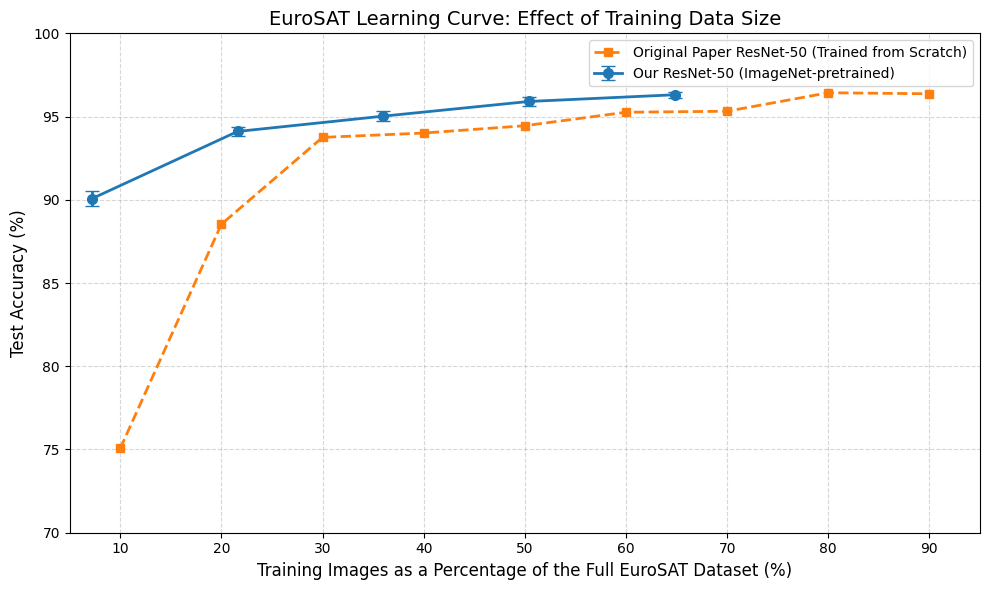


Our training proportions:
10% of original training data = 7.2% of full EuroSAT dataset
30% of original training data = 21.6% of full EuroSAT dataset
50% of original training data = 36.0% of full EuroSAT dataset
70% of original training data = 50.4% of full EuroSAT dataset
90% of original training data = 64.8% of full EuroSAT dataset

Learning curve saved to:
/content/drive/MyDrive/EuroSAT_Final_Experiments/Part_A/Results/Final_Test_Evaluation_GPU_2026-11-05_Run2/part_a_learning_curve.png


In [41]:
# ============================================================
# 6.2 Plot the Learning Curve and Compare with the Original Paper
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


# ============================================================
# 1. Load Our Experimental Summary
# ============================================================

PART_A_SUMMARY_FILE = (
    PART_A_RESULTS_DIR / "part_a_results_summary.csv"
)

if not PART_A_SUMMARY_FILE.exists():
    raise FileNotFoundError(
        "Part A summary file not found. "
        "Please complete Section 6.1 first."
    )

summary_df = pd.read_csv(PART_A_SUMMARY_FILE)


# ============================================================
# 2. Verify Dataset Proportions and Summary Values
# ============================================================

assert len(summary_df) == len(TRAINING_SHARES), (
    "Unexpected number of training proportions."
)

assert not summary_df.isnull().any().any(), (
    "Missing values found in the summary results."
)

assert len(train_df) == 19440, (
    "The original training partition has an unexpected size."
)

assert len(splits_df) == 27000, (
    "The complete EuroSAT dataset has an unexpected size."
)


# ============================================================
# 3. Convert Our Training Shares to Full Dataset Percentages
# ============================================================

# Our training shares are percentages of the original
# training partition (19,440 images).

# Convert them into percentages of the complete dataset
# (27,000 images) for comparison with the original paper.

original_training_fraction = (
    len(train_df) / len(splits_df)
)

our_training_shares = (
    summary_df["training_share"]
    * original_training_fraction
    * 100
)


# ============================================================
# 4. Convert Accuracy Values to Percentages
# ============================================================

our_mean_accuracy = (
    summary_df["test_accuracy_mean"] * 100
)

our_std_accuracy = (
    summary_df["test_accuracy_std"] * 100
)


# ============================================================
# 5. Original Paper: ResNet-50 Trained from Scratch
#    Values Taken from Table II
# ============================================================

# Training proportions of the complete EuroSAT dataset

paper_training_shares = [
    10, 20, 30, 40, 50, 60, 70, 80, 90
]

paper_resnet50_accuracy = [
    75.06, 88.53, 93.75, 94.01, 94.45,
    95.26, 95.32, 96.43, 96.37
]


# ============================================================
# 6. Create the Learning Curve
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))


# ------------------------------------------------------------
# Our ImageNet-pretrained ResNet-50
# ------------------------------------------------------------

ax.errorbar(
    our_training_shares,
    our_mean_accuracy,
    yerr=our_std_accuracy,
    marker="o",
    markersize=7,
    linewidth=2,
    capsize=5,
    label="Our ResNet-50 (ImageNet-pretrained)"
)


# ------------------------------------------------------------
# Original Paper's ResNet-50 Trained from Scratch
# ------------------------------------------------------------

ax.plot(
    paper_training_shares,
    paper_resnet50_accuracy,
    marker="s",
    markersize=6,
    linewidth=2,
    linestyle="--",
    label="Original Paper ResNet-50 (Trained from Scratch)"
)


# ============================================================
# 7. Format the Plot
# ============================================================

ax.set_title(
    "EuroSAT Learning Curve: Effect of Training Data Size",
    fontsize=14
)

ax.set_xlabel(
    "Training Images as a Percentage of the Full EuroSAT Dataset (%)",
    fontsize=12
)

ax.set_ylabel(
    "Test Accuracy (%)",
    fontsize=12
)

ax.set_xticks(paper_training_shares)

ax.set_xlim(5, 95)

ax.set_ylim(70, 100)

ax.grid(
    True,
    linestyle="--",
    alpha=0.5
)

ax.legend(fontsize=10)

fig.tight_layout()


# ============================================================
# 8. Save and Display the Learning Curve
# ============================================================

LEARNING_CURVE_PATH = (
    PART_A_RESULTS_DIR / "part_a_learning_curve.png"
)

fig.savefig(
    LEARNING_CURVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 9. Display Training Proportion Conversion
# ============================================================

print("\nOur training proportions:")

for share, percentage in zip(
    summary_df["training_share"],
    our_training_shares
):
    print(
        f"{share * 100:.0f}% of original training data "
        f"= {percentage:.1f}% of full EuroSAT dataset"
    )

print(
    f"\nLearning curve saved to:\n"
    f"{LEARNING_CURVE_PATH}"
)

### 6.3 Comparison with the Original Paper

The experimental results are compared with the ResNet-50 results reported in the original EuroSAT paper by Helber et al. (2019).

In Table II, the authors report ResNet-50 classification accuracies using different training-test proportions. These networks were trained from scratch, without ImageNet-pretrained weights. In contrast, the ResNet-50 model used in this study was pretrained on ImageNet and subsequently fine-tuned on EuroSAT.

The original paper reports that the ResNet-50 trained from scratch achieves 75.06% accuracy with a 10/90 training-test split and 96.43% with an 80/20 split. The results generally demonstrate that classification performance improves as more training data becomes available, although small variations occur at higher training proportions.

In our experiments, the ImageNet-pretrained ResNet-50 achieves a mean test accuracy of **90.07% ± 0.43%** using 10% of the original training partition (1,944 images). When the training proportion increases to 90% (17,496 images), the mean test accuracy reaches **96.31% ± 0.17%**. These results are calculated across three random seeds (42, 43, and 44).

The results indicate that increasing the amount of labelled training data improves classification performance. The largest improvement occurs between the 10% and 30% training proportions, while the performance gains become smaller at higher training proportions. This suggests that the model benefits substantially from additional labelled data at lower training proportions, with diminishing improvements as more training data becomes available.

An important difference between the two experimental setups must be considered. In our study, the training proportions (10%, 30%, 50%, 70%, and 90%) represent fractions of the original training partition of 19,440 images. The validation set of 2,160 images and test set of 5,400 images remain fixed throughout the experiments. Consequently, our training proportions correspond to 7.2%, 21.6%, 36.0%, 50.4%, and 64.8% of the complete EuroSAT dataset, respectively. In the original paper, the percentages in Table II represent different training-test proportions of the dataset.

Therefore, the comparison is indicative rather than a direct, controlled comparison. Differences in training data proportions, dataset splitting, and pretrained versus randomly initialized weights mean that the observed performance differences cannot be attributed to ImageNet pretraining alone.

The original paper also reports **98.57% accuracy** for a fine-tuned, ImageNet-pretrained ResNet-50 using RGB images in Table III. In comparison, our highest mean test accuracy is 96.31% ± 0.17%, resulting in a difference of approximately **2.26 percentage points**. However, this result is a separate reference point rather than a directly comparable result because the experimental settings and data splits differ.

Overall, the experiments demonstrate that an ImageNet-pretrained ResNet-50 can achieve strong classification performance with a reduced amount of labelled EuroSAT training data. The learning curve also shows that the amount of labelled training data influences classification performance, although the improvements become smaller at higher training proportions.